# Organização do Ambiente

Importando Bibliotecas:

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


Acessando no Google Drive:

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Importando o Dataset:

In [ ]:
dataset = pd.read_csv( '/content/drive/MyDrive/TrabalhoMarcio/Dataset/PhiUSIIL_Phishing_URL_Dataset.csv', sep=',', on_bad_lines='skip' )

# Tratamento de Dados:

## Verificando se houve perda de dados:

In [ ]:
print("Formato:", dataset.shape)

Formato: (235795, 56)


In [ ]:
print(dataset.columns.tolist())

['FILENAME', 'URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef', 'label']


## Variavel-alvo:

In [ ]:
y = dataset['label']

## Remoção das colunas que não serão utilizadas no treinamento

In [ ]:
X = dataset.drop( columns=['FILENAME', 'URL', 'Domain', 'Title', 'label'] )

## Verificando nulos:

In [ ]:
print("\nPercentual de nulos (%):")
print((dataset.isna().mean()*100).round(2))


Percentual de nulos (%):
FILENAME                      0.0
URL                           0.0
URLLength                     0.0
Domain                        0.0
DomainLength                  0.0
IsDomainIP                    0.0
TLD                           0.0
URLSimilarityIndex            0.0
CharContinuationRate          0.0
TLDLegitimateProb             0.0
URLCharProb                   0.0
TLDLength                     0.0
NoOfSubDomain                 0.0
HasObfuscation                0.0
NoOfObfuscatedChar            0.0
ObfuscationRatio              0.0
NoOfLettersInURL              0.0
LetterRatioInURL              0.0
NoOfDegitsInURL               0.0
DegitRatioInURL               0.0
NoOfEqualsInURL               0.0
NoOfQMarkInURL                0.0
NoOfAmpersandInURL            0.0
NoOfOtherSpecialCharsInURL    0.0
SpacialCharRatioInURL         0.0
IsHTTPS                       0.0
LineOfCode                    0.0
LargestLineLength             0.0
HasTitle              

## Verificando Duplicados:

In [ ]:
print("Quantidade de registros duplicados:")
print(dataset.duplicated().sum())

print("\nPercentual de duplicados (%):")
print(round(dataset.duplicated().mean() * 100, 2))

Quantidade de registros duplicados:
0

Percentual de duplicados (%):
0.0


## Verificando Variavel-alvo:

In [ ]:
print("\nDistribuição do alvo (label):")
print(dataset["label"].value_counts(dropna=False, normalize=True).round(3))


Distribuição do alvo (label):
label
1    0.572
0    0.428
Name: proportion, dtype: float64


# Separando dados de Entrada e Referencia:

In [ ]:
# Características de entrada
X = dataset.drop(
    columns=['FILENAME', 'URL', 'Domain', 'Title', 'label']
)

# Variável-alvo
y = dataset['label']

## Verificando colunas categóricas ou textuais:

In [ ]:
print(X.select_dtypes(include=['object', 'category']).columns.tolist())

['TLD']


Verificando o que tem na coluna TLD:

In [ ]:
print(X['TLD'].value_counts())
print("\nQuantidade de categorias:", X['TLD'].nunique())

TLD
com           112554
org            18793
net             7097
app             6508
uk              6395
               ...  
15                 1
nr                 1
parts              1
kitchen            1
associates         1
Name: count, Length: 695, dtype: int64

Quantidade de categorias: 695


Verificando Y(não vai precisar de enconding):

In [ ]:
# Classes existentes
print(y.value_counts())

# Tipos de dados e valores ausentes
print(y.dtype)
print("Valores ausentes:", y.isna().sum())

label
1    134850
0    100945
Name: count, dtype: int64
int64
Valores ausentes: 0


# Separando o Dataset

In [ ]:
from sklearn.model_selection import train_test_split

# Divisão dos dados: 80% para treino e 20% para teste
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Conferir os resultados
print("X_treino:", X_treino.shape)
print("X_teste:", X_teste.shape)
print("y_treino:", y_treino.shape)
print("y_teste:", y_teste.shape)

X_treino: (188636, 51)
X_teste: (47159, 51)
y_treino: (188636,)
y_teste: (47159,)


Arrumando a variavel TLD:

In [ ]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

# Criar o codificador para a variável TLD
codificador = ColumnTransformer(
    transformers=[
        ('encoder', OneHotEncoder(handle_unknown='ignore'), ['TLD'])
    ],
    remainder='passthrough'
)

# Ajustar o codificador com os dados de treino
X_treino_codificado = codificador.fit_transform(X_treino)

# Aplicar o mesmo codificador aos dados de teste
X_teste_codificado = codificador.transform(X_teste)

# Conferir as dimensões após a codificação
print("X_treino_codificado:", X_treino_codificado.shape)
print("X_teste_codificado:", X_teste_codificado.shape)

X_treino_codificado: (188636, 717)
X_teste_codificado: (47159, 717)


# Treinando os modelos:

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Modelo 1: Árvore de Decisão
arvore_decisao = DecisionTreeClassifier(
    random_state=42
)

arvore_decisao.fit(X_treino_codificado, y_treino)

# Modelo 2: Random Forest
random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

random_forest.fit(X_treino_codificado, y_treino)

print("Os dois modelos foram treinados com sucesso.")

Os dois modelos foram treinados com sucesso.


## Fase teste: Treinando sem a URLSimilarity

Essa fase foi implementada aqui por conta da ordem do notebookLM

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
import numpy as np

# Obter o nome exato da característica gerada pelo ColumnTransformer
nomes_features = list(codificador.get_feature_names_out())
coluna_alvo_codificada = "remainder__URLSimilarityIndex"

if coluna_alvo_codificada in nomes_features:
    # Identificar o índice da coluna que queremos remover
    idx = nomes_features.index(coluna_alvo_codificada)

    # Selecionar todas as colunas exceto a de índice 'idx'
    indices_manter = [i for i in range(len(nomes_features)) if i != idx]

    # Fatiar as matrizes esparsas do SciPy usando os índices
    X_treino_sem_similarity = X_treino_codificado[:, indices_manter]
    X_teste_sem_similarity = X_teste_codificado[:, indices_manter]
    print(f"Coluna '{coluna_alvo_codificada}' removida com sucesso. Nova dimensão: {X_treino_sem_similarity.shape[1]} colunas.")
else:
    X_treino_sem_similarity = X_treino_codificado
    X_teste_sem_similarity = X_teste_codificado
    print("Coluna não encontrada. Utilizando matriz original.")

# Reproduzir os parâmetros do modelo original.
arvore_sem_similarity = DecisionTreeClassifier(
    random_state=42
)

arvore_sem_similarity.fit(X_treino_sem_similarity, y_treino)

predicoes = arvore_sem_similarity.predict(X_teste_sem_similarity)

print("\nAcurácia:", accuracy_score(y_teste, predicoes))
print("Matriz de confusão:")
print(confusion_matrix(y_teste, predicoes))
print("Profundidade:", arvore_sem_similarity.get_depth())
print("Número de folhas:", arvore_sem_similarity.get_n_leaves())

Coluna 'remainder__URLSimilarityIndex' removida com sucesso. Nova dimensão: 716 colunas.

Acurácia: 0.9989397569923026
Matriz de confusão:
[[20168    21]
 [   29 26941]]
Profundidade: 28
Número de folhas: 227


# Comparação:


Modelo: Árvore de Decisão

Matriz de Confusão:
[[20189     0]
 [    0 26970]]

Relatório de Classificação:
              precision    recall  f1-score   support

Phishing (0)     1.0000    1.0000    1.0000     20189
Legítimo (1)     1.0000    1.0000    1.0000     26970

    accuracy                         1.0000     47159
   macro avg     1.0000    1.0000    1.0000     47159
weighted avg     1.0000    1.0000    1.0000     47159

Acurácia: 1.0000


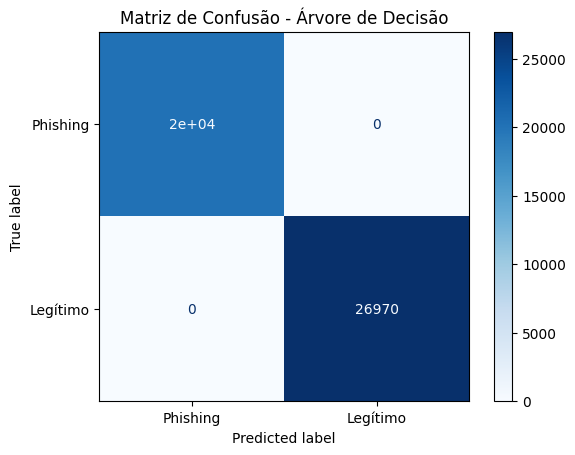


Modelo: Random Forest

Matriz de Confusão:
[[20189     0]
 [    0 26970]]

Relatório de Classificação:
              precision    recall  f1-score   support

Phishing (0)     1.0000    1.0000    1.0000     20189
Legítimo (1)     1.0000    1.0000    1.0000     26970

    accuracy                         1.0000     47159
   macro avg     1.0000    1.0000    1.0000     47159
weighted avg     1.0000    1.0000    1.0000     47159

Acurácia: 1.0000


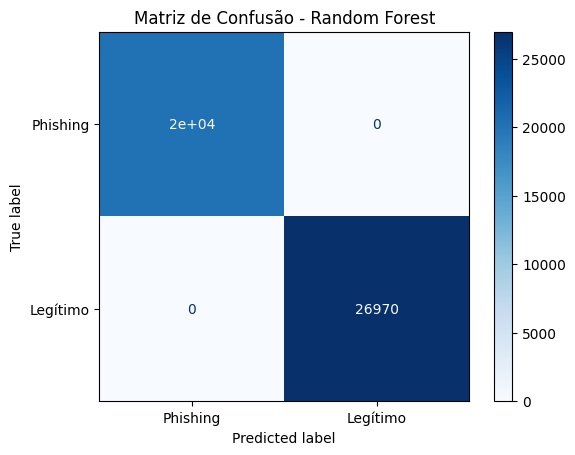

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    accuracy_score
)
import matplotlib.pyplot as plt

# Modelos a avaliar
modelos = {
    "Árvore de Decisão": arvore_decisao,
    "Random Forest": random_forest
}

for nome, modelo in modelos.items():

    # Gerar previsões usando os dados de teste
    y_pred = modelo.predict(X_teste_codificado)

    # Matriz de confusão
    cm = confusion_matrix(y_teste, y_pred, labels=[0, 1])

    print(f"\n{'=' * 60}")
    print(f"Modelo: {nome}")
    print("\nMatriz de Confusão:")
    print(cm)

    # Precisão, recall e F1-score de cada classe
    print("\nRelatório de Classificação:")
    print(classification_report(
        y_teste,
        y_pred,
        labels=[0, 1],
        target_names=["Phishing (0)", "Legítimo (1)"],
        digits=4,
        zero_division=0
    ))

    # Acurácia complementar
    print(f"Acurácia: {accuracy_score(y_teste, y_pred):.4f}")

    # Visualização da matriz de confusão
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Phishing", "Legítimo"]
    ).plot(cmap=plt.cm.Blues)

    plt.title(f"Matriz de Confusão - {nome}")
    plt.show()

## Vendo se o 100% esta correto

A verificação abaixo compõe verficações de vazamento da variavel-alvo, duplicados, importancia das variaveis, e a presença da variavel-alvo  

In [ ]:
import pandas as pd
import numpy as np

importancias = pd.Series(
    random_forest.feature_importances_,
    index=codificador.get_feature_names_out()
)

print("10 características mais importantes:")
print(importancias.sort_values(ascending=False).head(10))

10 características mais importantes:
remainder__URLSimilarityIndex    0.128104
remainder__LineOfCode            0.112598
remainder__NoOfSelfRef           0.090930
remainder__NoOfImage             0.078561
remainder__NoOfExternalRef       0.069449
remainder__NoOfCSS               0.056004
remainder__NoOfJS                0.055557
remainder__LargestLineLength     0.043153
remainder__HasDescription        0.031216
remainder__HasCopyrightInfo      0.030354
dtype: float64


In [ ]:
print("Features usadas no modelo:", list(X.columns))
print("\nQuantidade de features:", len(X.columns))
print("\nO alvo 'label' está em X?", 'label' in X.columns)

Features usadas no modelo: ['URLLength', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef']

Quantidade de features: 51

O alvo 'label' está em X? False


In [ ]:
print("Linhas duplicadas no dataset original:", dataset.duplicated().sum())

print(
    "Linhas com características duplicadas em X:",
    X.duplicated().sum()
)

Linhas duplicadas no dataset original: 0
Linhas com características duplicadas em X: 808


In [ ]:
correlacoes = dataset.select_dtypes(
    include='number'
).corr()['label'].drop('label').abs().sort_values(
    ascending=False
)

print("10 características com maior correlação absoluta com o alvo:")
print(correlacoes.head(10))

10 características com maior correlação absoluta com o alvo:
URLSimilarityIndex       0.860358
HasSocialNet             0.784255
HasCopyrightInfo         0.743358
HasDescription           0.690232
IsHTTPS                  0.609132
DomainTitleMatchScore    0.584905
HasSubmitButton          0.578561
IsResponsive             0.548608
URLTitleMatchScore       0.539419
SpacialCharRatioInURL    0.533537
Name: label, dtype: float64


In [ ]:
# 1. Conferir os tamanhos das bases
print("Tamanho Treino:", len(y_treino))
print("Tamanho Teste:", len(y_teste))

# 2. Teste da árvore podada (profundidade 3)
from sklearn.tree import DecisionTreeClassifier
arvore_podada = DecisionTreeClassifier(max_depth=3, random_state=42)
arvore_podada.fit(X_treino_codificado, y_treino)

print(f"Acurácia Treino (depth=3): {arvore_podada.score(X_treino_codificado, y_treino):.4f}")
print(f"Acurácia Teste (depth=3):  {arvore_podada.score(X_teste_codificado, y_teste):.4f}")

# 3. Profundidade que a sua árvore original atingiu
print("Profundidade da sua Árvore original:", arvore_decisao.get_depth())
print("Número de folhas da sua Árvore original:", arvore_decisao.get_n_leaves())

Tamanho Treino: 188636
Tamanho Teste: 47159
Acurácia Treino (depth=3): 1.0000
Acurácia Teste (depth=3):  1.0000
Profundidade da sua Árvore original: 4
Número de folhas da sua Árvore original: 5


In [ ]:
# Adicionar os rótulos às características
treino = X_treino.copy()
treino['label'] = y_treino

teste = X_teste.copy()
teste['label'] = y_teste

# Identificar linhas idênticas, incluindo o rótulo
colunas = list(X.columns) + ['label']

treino_hash = pd.util.hash_pandas_object(
    treino[colunas], index=False
)
teste_hash = pd.util.hash_pandas_object(
    teste[colunas], index=False
)

hashes_treino = set(treino_hash)

correspondencias = teste_hash.isin(hashes_treino)

print("Linhas idênticas, incluindo o rótulo:",
      correspondencias.sum())

Linhas idênticas, incluindo o rótulo: 219


In [ ]:
# Comparar as características e os rótulos diretamente
colunas = list(X.columns) + ['label']

treino_completo = X_treino.copy()
treino_completo['label'] = y_treino

teste_completo = X_teste.copy()
teste_completo['label'] = y_teste

treino_tuplas = set(
    map(tuple, treino_completo[colunas].to_numpy())
)

teste_tuplas = list(
    map(tuple, teste_completo[colunas].to_numpy())
)

duplicadas = sum(
    linha in treino_tuplas for linha in teste_tuplas
)

print("Linhas do teste também presentes no treino:", duplicadas)
print("Percentual do teste:", round(duplicadas / len(X_teste) * 100, 4), "%")

Linhas do teste também presentes no treino: 219
Percentual do teste: 0.4644 %


In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix

# Ajustado para usar as instâncias já treinadas no notebook
modelos = {
    "Árvore de Decisão": arvore_decisao,
    "Random Forest": random_forest
}

for nome, modelo in modelos.items():
    # Ajustado para passar os dados de teste pré-processados/codificados
    y_pred = modelo.predict(X_teste_codificado)

    erros = (y_teste != y_pred).sum()
    acuracia = accuracy_score(y_teste, y_pred)

    print(f"\n{'=' * 45}")
    print(nome)
    print(f"{'=' * 45}")
    print(f"Acurácia: {acuracia:.10f}")
    print(f"Acurácia percentual: {acuracia * 100:.8f}%")
    print(f"Total de erros: {erros}")
    print(f"Total de acertos: {len(y_teste) - erros}")

    print("\nMatriz de confusão:")
    print(confusion_matrix(y_teste, y_pred))


Árvore de Decisão
Acurácia: 1.0000000000
Acurácia percentual: 100.00000000%
Total de erros: 0
Total de acertos: 47159

Matriz de confusão:
[[20189     0]
 [    0 26970]]

Random Forest
Acurácia: 1.0000000000
Acurácia percentual: 100.00000000%
Total de erros: 0
Total de acertos: 47159

Matriz de confusão:
[[20189     0]
 [    0 26970]]


In [ ]:
# 1. Verificar se 'label' aparece nas características
print("'label' em X_treino:", "label" in X_treino.columns)
print("'label' em X_teste_codificado:", "label" in X_teste_codificado.columns)

# 2. Comparar atributos, sem incluir os rótulos
# Usar as colunas originais de X, conforme o teste anterior
colunas_atributos = list(X.columns)

treino_atributos = set(
    map(tuple, X_treino[colunas_atributos].to_numpy())
)

teste_atributos = list(
    map(tuple, X_teste[colunas_atributos].to_numpy())
)

duplicadas_atributos = sum(
    linha in treino_atributos for linha in teste_atributos
)

print(
    "\nAmostras de teste com atributos idênticos aos do treino:",
    duplicadas_atributos
)
print(
    "Percentual:",
    round(duplicadas_atributos / len(X_teste) * 100, 4),
    "%"
)


'label' em X_treino: False
'label' em X_teste: False

Amostras de teste com atributos idênticos aos do treino: 219
Percentual: 0.4644 %


# Exportação

In [ ]:
import joblib

# Exportar a árvore de decisão já treinada
joblib.dump(arvore_decisao, "arvore_decisao.joblib")

# Exportar o pré-processador já ajustado
joblib.dump(codificador, "codificador.joblib")

print("Arquivos exportados com sucesso!")

Arquivos exportados com sucesso!


In [ ]:
from google.colab import files

files.download("codificador.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Comando de URL para teste no streamlit:

In [ ]:
# Selecionar uma URL classificada como phishing no dataset
exemplo_phishing = dataset.loc[
    dataset["label"] == 1, ["URL", "label"]
].sample(1, random_state=42)

display(exemplo_phishing)

,URL,label
157668,https://www.atelierozmoz.be,1
